Necessary modules for BDT

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import List, Dict, Any, Optional, Tuple
from IPython.display import display, HTML

import qiskit
from qiskit import QuantumCircuit, ClassicalRegister, transpile
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit_ibm_runtime.fake_provider import FakeQuitoV2

# Ensure output directory exists for saved figures
os.makedirs("out", exist_ok=True)

print(f"Qiskit Version: {qiskit.__version__}")


Qiskit Version: 2.5.2


This function determines whether the protocol will run over real ibm cloud quantum computer or a AerSimulator which is a C++ hardware simulation
# Parameters:
token (Optional[str]): IBM Quantum API token.
channel (str): Service channel (defaults to "ibm_quantum"; can also be "ibm_cloud").
instance (Optional[str]): IBM Cloud resource instance CRN or hub/group/project specification.
backend_name (Optional[str]): Name of a specific target backend (e.g., "ibm_sherbrooke"). If omitted, the least busy machine is chosen automatically.
min_num_qubits (int): Minimum required qubits when filtering for the least busy device (defaults to 12).

In [2]:
def get_ibm_backend(
    token: Optional[str] = None,
    channel: str = "ibm_quantum",
    instance: Optional[str] = None,
    backend_name: Optional[str] = None,
    min_num_qubits: int = 12
) -> Tuple[Any, bool]:
    """Initializes connection to IBM Cloud Quantum backend or falls back to AerSimulator."""
    if token and token.strip():
        try:
            print(f"Connecting to IBM Quantum Platform ({channel})...")
            service = QiskitRuntimeService(channel=channel, token=token.strip(), instance=instance)
            if backend_name and backend_name.strip():
                backend = service.backend(backend_name.strip())
                print(f"[ONLINE] Connected to IBM Quantum Hardware backend: {backend.name}")
            else:
                backend = service.least_busy(operational=True, simulator=False, min_num_qubits=min_num_qubits)
                print(f"[ONLINE] Selected least busy IBM Quantum Hardware: {backend.name} ({backend.num_qubits} qubits)")
            return backend, True
        except Exception as e:
            print(f"[FALLBACK] IBM Cloud connection failed ({e}). Falling back to local AerSimulator.")
            return AerSimulator(), False
    else:
        try:
            service = QiskitRuntimeService()
            if backend_name and backend_name.strip():
                backend = service.backend(backend_name.strip())
            else:
                backend = service.least_busy(operational=True, simulator=False, min_num_qubits=min_num_qubits)
            print(f"[ONLINE] Using saved IBM Quantum account with backend: {backend.name}")
            return backend, True
        except Exception:
            print("[LOCAL] No IBM Quantum token provided or saved. Running on AerSimulator (ISA-transpiled mode).")
            return AerSimulator(), False


The function prep_bell uses the quantum libraries to implement non standard bell states that are sepcified in the paper. 
1. **Paper Bell State Preparation:**
   - $|\Psi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$ (`H(a); CX(a,b)`)
   - $|\Psi^-\rangle = \frac{|00\rangle - |11\rangle}{\sqrt{2}}$ (`X(a); H(a); CX(a,b)`)
   - $|\Phi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}$ (`X(b); H(a); CX(a,b)`)
   - $|\Phi^-\rangle = \frac{|01\rangle - |10\rangle}{\sqrt{2}}$ (`X(a); X(b); H(a); CX(a,b)`)
In the bracket it is specified which gate to apply on the initial state to achieve the required bell state
H(a)  and CX(a,b) are common in all cases so they are done at last

In [3]:
# 2. Quantum Circuit Builders
BSM_CODE = {"Psi+": (0, 0), "Psi-": (1, 0), "Phi+": (0, 1), "Phi-": (1, 1)}
BSM_LABEL = {v: k for k, v in BSM_CODE.items()}

def prep_bell(qc: QuantumCircuit, a: int, b: int, label: str):
    """Prepare qubits (a, b) in paper Bell state."""
    if label == "Psi+":
        pass
    elif label == "Psi-":
        qc.x(a)
    elif label == "Phi+":
        qc.x(b)
    elif label == "Phi-":
        qc.x(a); qc.x(b)
    else:
        raise ValueError(f"Unknown Bell label: {label}")
    qc.h(a)
    qc.cx(a, b)

The below function is for performing bell state measurement on a two cubit pair $(a,b)$. First applies a control not gate with a as contorl bit and b as target bit for Entanglement Uncoupling and then applies a hadmard gate on a for basis transformation. then measures b into c_b and a into c_a

In [4]:
def bsm(qc: QuantumCircuit, a: int, b: int, c_a: int, c_b: int):
    """Bell State Measurement on ordered pair (a, b)."""
    qc.cx(a, b)
    qc.h(a)
    qc.measure(b, c_b)
    qc.measure(a, c_a)

This funtion is for building single-qubit verification circutis across non-orthogonal decoy states ($|0\rangle, |1\rangle, |+\rangle, |-\rangle$) to detect channel eavesdropping and disturbance. measure it for ka==0 and reflect it back for ka==1

In [5]:
def build_decoy_circuits(decoy_states: List[str], ka: List[int]) -> List[QuantumCircuit]:
    """Build single-qubit circuits for decoy state verification."""
    circs = []
    for j, (st, ka_bit) in enumerate(zip(decoy_states, ka)):
        qc = QuantumCircuit(1, 1, name=f"decoy_{j}")
        if st in ("1", "-"):
            qc.x(0)
        if st in ("+", "-"):
            qc.h(0)
        if ka_bit == 0:
            qc.measure(0, 0)
        else:
            qc.h(0)
            qc.measure(0, 0)
        circs.append(qc)
    return circs

4. **Identity Authentication Circuit (Fig. 3):** $2n$ qubits with BSM for Subset $A$ ($k_a = k_b$) and $Z$-basis measurements for Subset $B$ ($k_a \neq k_b$).

In [6]:
def build_identity_auth_circuit(n: int, ka: List[int], kb: List[int]) -> QuantumCircuit:
    """Fig. 3: Identity Authentication circuit on 2n qubits."""
    qc = QuantumCircuit(2 * n, 2 * n, name="fig3_id_auth")
    for i in range(n):
        lab = "Phi+" if kb[i] == 0 else "Phi-"
        prep_bell(qc, 2 * i, 2 * i + 1, lab)
    qc.barrier()
    for i in range(n):
        if ka[i] == kb[i]:
            bsm(qc, 2 * i, 2 * i + 1, 2 * i, 2 * i + 1)
        else:
            qc.measure(2 * i + 1, 2 * i + 1)
            qc.measure(2 * i, 2 * i)
    return qc

   - **Fig. 4 (SP $\to$ SM):** $3n$ qubits ($w, S_3, S_4$) with BSM on $(w, S_3)$ and $Z$-measurement of $S_4$.
   - **Fig. 5 (SM $\to$ SP):** $2n$ qubits ($S_5, S_6$) with $Z$-measurements of $S_6$ and $S_5$.

In [7]:
def build_sp_to_sm_circuit(n: int, omega_sp: List[int]) -> QuantumCircuit:
    """Fig. 4: SP -> SM Quantum Message Transmission circuit on 3n qubits."""
    qc = QuantumCircuit(3 * n, 3 * n, name="fig4_sp_to_sm")
    for i in range(n):
        w, s3, s4 = 3 * i, 3 * i + 1, 3 * i + 2
        if omega_sp[i] == 1:
            qc.x(w)
        prep_bell(qc, s3, s4, "Psi+")
    qc.barrier()
    for i in range(n):
        w, s3, s4 = 3 * i, 3 * i + 1, 3 * i + 2
        qc.cx(w, s3)
        qc.measure(s4, s4)
        qc.h(w)
        qc.measure(s3, s3)
        qc.measure(w, w)
    return qc

def build_sm_to_sp_circuit(n: int) -> QuantumCircuit:
    """Fig. 5: SM -> SP Classical Duplex Transmission circuit on 2n qubits."""
    qc = QuantumCircuit(2 * n, 2 * n, name="fig5_sm_to_sp")
    for i in range(n):
        s5, s6 = 2 * i, 2 * i + 1
        prep_bell(qc, s5, s6, "Psi-")
    qc.barrier()
    for i in range(n):
        s5, s6 = 2 * i, 2 * i + 1
        qc.measure(s6, s6)
        qc.measure(s5, s5)
    return qc

print("Quantum circuit templates initialized successfully.")


Quantum circuit templates initialized successfully.


•	ka (List[int]): Derived binary key sequence for party A ($K_A$).
•	kb (List[int]): Derived binary key sequence for party B ($K_B$).
•	decoy_slots (List[int]): 1-based transmission slot indices allocated for decoy state transmission.
•	decoy_states (List[str]): Quantum decoy state basis designations ("0", "1", "+", "-").
•	e_SM (float): Measured decoy state error rate for the Smart Meter ($Z$-basis).
•	e_SP (float): Measured decoy state error rate for the Service Provider ($X$-basis).
•	A_indices (List[int]): Pair indices where $K_A[i] == K_B[i]$ (Bell measurement branch in authentication).
•	B_indices (List[int]): Pair indices where $K_A[i] \neq K_B[i]$ (single-qubit measurement branch in authentication).
•	identity_rate_A (float): Authentication fidelity rate across $A$-indices.
•	identity_rate_B (float): Authentication fidelity rate across $B$-indices.
•	warnings (List[str]): Warning notices logged during protocol execution.
•	bsm_labels (List[str]): Observed Bell state measurement labels ("Psi+", "Psi-", "Phi+", "Phi-").
•	omega_SP_recovered (List[int]): Demodulated message bits transmitted from SP to SM ($\omega_{SP}$).
•	omega_SM_recovered (List[int]): Demodulated message bits transmitted from SM to SP ($\omega_{SM}$).
•	MAC_SP (str): Target message authentication code for SP ($K_A \oplus \omega_{SP}$).
•	MAC_SM (str): Target message authentication code for SM ($K_B \oplus \omega_{SM}$).
•	pass_SM (List[bool]): Per-bit MAC validation flags for message received by SM.
•	pass_SP (List[bool]): Per-bit MAC validation flags for message received by SP.
•	aborted_at (Optional[str]): Abort stage identifier ("step2", "step3", "step5", or None if completed).
•	success (bool): Overall protocol outcome flag (True if all verification thresholds are met).
•	eta (float): Theoretical quantum channel efficiency percentage ($\frac{8n}{8.5n} \times 100%$).
•	backend_name (str): Name of the executing backend (e.g., target QPU or aer_simulator).
•	step_log (List[str]): Chronological event traces logged during protocol execution (default: []).


In [8]:
# 3. IBM Quantum Protocol Orchestrator
@dataclass
class Report:
    ka: List[int]
    kb: List[int]
    decoy_slots: List[int]
    decoy_states: List[str]
    e_SM: float
    e_SP: float
    A_indices: List[int]
    B_indices: List[int]
    identity_rate_A: float
    identity_rate_B: float
    warnings: List[str]
    bsm_labels: List[str]
    omega_SP_recovered: List[int]
    omega_SM_recovered: List[int]
    MAC_SP: str
    MAC_SM: str
    pass_SM: List[bool]
    pass_SP: List[bool]
    aborted_at: Optional[str]
    success: bool
    eta: float
    backend_name: str
    step_log: List[str] = field(default_factory=list)

def run_protocol_ibm(
    n: int,
    kab: str,
    omega_sp: str,
    omega_sm: str,
    backend: Any,
    shots: int = 1024,
    seed: Optional[int] = 42,
    decoy_slots: Optional[List[int]] = None,
    decoy_states: Optional[List[str]] = None,
    tau_d: float = 0.20,
    tau_id: float = 0.80,
    tau_msg: float = 0.80
) -> Report:
    """Execute BDT protocol on IBM Quantum hardware or local simulator using SamplerV2."""
    rng = np.random.default_rng(seed)
    ka = [int(kab[2 * i]) for i in range(n)]
    kb = [int(kab[2 * i + 1]) for i in range(n)]
    w_sp = [int(b) for b in omega_sp]
    w_sm = [int(b) for b in omega_sm]
    D = n // 2

    log = []
    def log_step(msg):
        log.append(msg)
        print(msg)

    backend_name = getattr(backend, "name", "aer_simulator")
    log_step(f"--- IBM Quantum BDT Protocol: n={n}, Target Backend={backend_name} ---")
    log_step(f"Derived Keys: ka={''.join(map(str, ka))}, kb={''.join(map(str, kb))}")

    warnings = []
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    sampler = Sampler(mode=backend)

    # Step 1: Preparation & Decoy States
    if decoy_states is None:
        decoy_states = []
        for j in range(D):
            b = int(rng.integers(0, 2))
            if ka[j] == 0:
                st = "0" if b == 0 else "1"
            else:
                st = "+" if b == 0 else "-"
            decoy_states.append(st)

    expected_decoy_bits = [0 if st in ("0", "+") else 1 for st in decoy_states]
    total_slots = n + D
    if decoy_slots is None:
        slot_indices_0based = sorted([int(s) for s in rng.choice(total_slots, size=D, replace=False)])
        decoy_slots_1based = [s + 1 for s in slot_indices_0based]
    else:
        decoy_slots_1based = decoy_slots
        slot_indices_0based = [s - 1 for s in decoy_slots_1based]

    log_step(f"Step 1 (SP Prep): Decoys at slots {decoy_slots_1based}, states={decoy_states}, bits={expected_decoy_bits}")

    # Step 2: Distribution & Eavesdropping Detection (Decoys)
    decoy_circs = build_decoy_circuits(decoy_states, ka)
    isa_decoys = [pm.run(qc) for qc in decoy_circs]
    decoy_jobs = sampler.run(isa_decoys, shots=shots)
    decoy_results = decoy_jobs.result()

    e_SM_errors, e_SM_total = 0, 0
    e_SP_errors, e_SP_total = 0, 0
    for j in range(D):
        c_dict = decoy_results[j].data.c.get_counts()
        exp_bit = expected_decoy_bits[j]
        tot_shots = sum(c_dict.values())
        err_shots = sum(cnt for b_str, cnt in c_dict.items() if int(b_str) != exp_bit)
        if ka[j] == 0:
            e_SM_errors += err_shots
            e_SM_total += tot_shots
        else:
            e_SP_errors += err_shots
            e_SP_total += tot_shots

    e_SM = e_SM_errors / e_SM_total if e_SM_total > 0 else 0.0
    e_SP = e_SP_errors / e_SP_total if e_SP_total > 0 else 0.0
    log_step(f"Step 2 (Eavesdropping Check): e_SM={e_SM:.4f}, e_SP={e_SP:.4f} (Threshold={tau_d})")

    eta_val = (8.0 * n) / (8.5 * n) * 100.0
    if e_SM > tau_d or e_SP > tau_d:
        log_step("Step 2 ABORT: Decoy error exceeded threshold!")
        return Report(
            ka=ka, kb=kb, decoy_slots=decoy_slots_1based, decoy_states=decoy_states,
            e_SM=e_SM, e_SP=e_SP, A_indices=[], B_indices=[], identity_rate_A=0.0, identity_rate_B=0.0,
            warnings=warnings, bsm_labels=[], omega_SP_recovered=[], omega_SM_recovered=[],
            MAC_SP="", MAC_SM="", pass_SM=[], pass_SP=[], aborted_at="step2", success=False,
            eta=eta_val, backend_name=backend_name, step_log=log
        )

    # Step 3: Mutual Identity Authentication (Fig. 3)
    qc_id = build_identity_auth_circuit(n, ka, kb)
    isa_id = pm.run(qc_id)
    id_counts = sampler.run([isa_id], shots=shots).result()[0].data.c.get_counts()

    A_indices = [i for i in range(n) if ka[i] == kb[i]]
    B_indices = [i for i in range(n) if ka[i] != kb[i]]
    match_A, tot_A = 0, 0
    match_B, tot_B = 0, 0

    for bitstring, count in id_counts.items():
        c = [int(x) for x in bitstring.replace(" ", "")[::-1]]
        for i in A_indices:
            m_s1, m_s2 = c[2 * i], c[2 * i + 1]
            if BSM_LABEL.get((m_s1, m_s2)) == ("Phi+" if kb[i] == 0 else "Phi-"):
                match_A += count
            tot_A += count
        for i in B_indices:
            m_s1, m_s2 = c[2 * i], c[2 * i + 1]
            if m_s1 != m_s2:
                match_B += count
            tot_B += count

    id_rate_A = match_A / tot_A if tot_A > 0 else 0.0
    id_rate_B = match_B / tot_B if tot_B > 0 else 0.0
    log_step(f"Step 3 (Identity Auth): SP->SM (A={A_indices}) match={id_rate_A:.4f}; SM->SP (B={B_indices}) match={id_rate_B:.4f}")

    if (
    tot_A == 0
    or tot_B == 0
    or id_rate_A < tau_id
    or id_rate_B < tau_id
    ):
        log_step("Step 3 ABORT: Identity authentication failed!")
        return Report(
            ka=ka, kb=kb, decoy_slots=decoy_slots_1based, decoy_states=decoy_states,
            e_SM=e_SM, e_SP=e_SP, A_indices=A_indices, B_indices=B_indices,
            identity_rate_A=id_rate_A, identity_rate_B=id_rate_B,
            warnings=warnings, bsm_labels=[], omega_SP_recovered=[], omega_SM_recovered=[],
            MAC_SP="", MAC_SM="", pass_SM=[], pass_SP=[], aborted_at="step3", success=False,
            eta=eta_val, backend_name=backend_name, step_log=log
        )

    # Step 4: Duplex Communication (Fig. 4 & Fig. 5)
    qc_sp_sm = build_sp_to_sm_circuit(n, w_sp)
    isa_sp_sm = pm.run(qc_sp_sm)
    counts_sp_sm = sampler.run([isa_sp_sm], shots=shots).result()[0].data.c.get_counts()
    best_sp = max(counts_sp_sm.items(), key=lambda kv: kv[1])[0]
    c_sp = [int(x) for x in best_sp.replace(" ", "")[::-1]]
    omega_sp_rec = [c_sp[3 * i + 2] ^ c_sp[3 * i + 1] for i in range(n)]
    bsm_labels = [BSM_LABEL.get((c_sp[3 * i], c_sp[3 * i + 1]), "?") for i in range(n)]

    qc_sm_sp = build_sm_to_sp_circuit(n)
    isa_sm_sp = pm.run(qc_sm_sp)
    counts_sm_sp = sampler.run([isa_sm_sp], shots=shots).result()[0].data.c.get_counts()
    best_sm = max(counts_sm_sp.items(), key=lambda kv: kv[1])[0]
    c_sm = [int(x) for x in best_sm.replace(" ", "")[::-1]]
    omega_sm_rec = [ c_sm[2 * i] ^ (1 if w_sm[i] != c_sm[2 * i + 1] else 0) for i in range(n) ]

    log_step(f"Step 4 (Duplex Comms): SP->SM: {''.join(map(str, omega_sp_rec))} ; SM->SP: {''.join(map(str, omega_sm_rec))}")

    # Step 5: Mutual MAC Verification
    mac_sp_bits = [ka[i] ^ w_sp[i] for i in range(n)]
    mac_sm_bits = [kb[i] ^ w_sm[i] for i in range(n)]
    mac_sp_str = "".join(map(str, mac_sp_bits))
    mac_sm_str = "".join(map(str, mac_sm_bits))
    pass_sm = [mac_sp_bits[i] == (ka[i] ^ omega_sp_rec[i]) for i in range(n)]
    pass_sp = [mac_sm_bits[i] == (kb[i] ^ omega_sm_rec[i]) for i in range(n)]
    rate_sm = sum(pass_sm) / n
    rate_sp = sum(pass_sp) / n
    log_step(f"Step 5 (MAC Check): MAC_SP={mac_sp_str}, MAC_SM={mac_sm_str}; pass_sm={rate_sm:.2f}, pass_sp={rate_sp:.2f}")

    if rate_sm < tau_msg or rate_sp < tau_msg:
        log_step("Step 5 ABORT: MAC check failed!")
        return Report(
            ka=ka, kb=kb, decoy_slots=decoy_slots_1based, decoy_states=decoy_states,
            e_SM=e_SM, e_SP=e_SP, A_indices=A_indices, B_indices=B_indices,
            identity_rate_A=id_rate_A, identity_rate_B=id_rate_B,
            warnings=warnings, bsm_labels=bsm_labels, omega_SP_recovered=omega_sp_rec,
            omega_SM_recovered=omega_sm_rec, MAC_SP=mac_sp_str, MAC_SM=mac_sm_str,
            pass_SM=pass_sm, pass_SP=pass_sp, aborted_at="step5", success=False,
            eta=eta_val, backend_name=backend_name, step_log=log
        )

    log_step(f"Protocol SUCCESS: Verified successfully on {backend_name}.")
    return Report(
        ka=ka, kb=kb, decoy_slots=decoy_slots_1based, decoy_states=decoy_states,
        e_SM=e_SM, e_SP=e_SP, A_indices=A_indices, B_indices=B_indices,
        identity_rate_A=id_rate_A, identity_rate_B=id_rate_B,
        warnings=warnings, bsm_labels=bsm_labels, omega_SP_recovered=omega_sp_rec,
        omega_SM_recovered=omega_sm_rec, MAC_SP=mac_sp_str, MAC_SM=mac_sm_str,
        pass_SM=pass_sm, pass_SP=pass_sp, aborted_at=None, success=True,
        eta=eta_val, backend_name=backend_name, step_log=log
    )

print("IBM Quantum Protocol Engine defined.")


IBM Quantum Protocol Engine defined.


In [9]:
# ==============================================================================
# 1. IBM CLOUD / QUANTUM PLATFORM CREDENTIALS
# ==============================================================================
# To target real IBM Quantum hardware, paste your token below:
IBM_QUANTUM_TOKEN = ""         # API Token from https://quantum.ibm.com/ (or leave blank)
IBM_CHANNEL = "ibm_quantum"    # 'ibm_quantum' or 'ibm_cloud'
IBM_INSTANCE = None            # CRN string (e.g. 'crn:v1:bluemix:...') if using ibm_cloud
BACKEND_NAME = None            # e.g. 'ibm_kyiv', 'ibm_sherbrooke', or None for auto least-busy
SHOTS = 8192                  # Measurement shots per circuit

# ==============================================================================
# 2. PROTOCOL PARAMETER SELECTION
# ==============================================================================
n = 4                          # Message length: must be an even integer >= 2
kab = "00110010"               # Interleaved pre-shared key (length 2n)
omega_sp = "0101"              # SP's quantum message (length n)
omega_sm = "1010"              # SM's classical message (length n)
seed = 42                      # Random seed for reproducible decoy selection

# Simulation variable aliases
OMEGA_SP = omega_sp
OMEGA_SM = omega_sm
SEED = seed

# Decision thresholds (0.20 / 0.80 provides tolerance for physical hardware noise)
tau_d = 0.20                   # Decoy error rate threshold
tau_id = 0.80                  # Identity authentication threshold
tau_msg = 0.80                 # Message authentication threshold

# --- Input Validation ---
assert isinstance(n, int) and n >= 2 and n % 2 == 0, f"n must be even >= 2, got {n}"
assert len(kab) == 2 * n and set(kab).issubset({"0", "1"}), f"kab must be binary length {2*n}"
assert len(omega_sp) == n and set(omega_sp).issubset({"0", "1"}), f"omega_sp must be binary length {n}"
assert len(omega_sm) == n and set(omega_sm).issubset({"0", "1"}), f"omega_sm must be binary length {n}"

# Initialize Target Backend
target_backend, is_real_qpu = get_ibm_backend(
    token=IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN.strip() else None,
    channel=IBM_CHANNEL,
    instance=IBM_INSTANCE,
    backend_name=BACKEND_NAME,
    min_num_qubits=3 * n
)

print("\nProtocol Parameters Ready:")
print(f"  Target Backend: {getattr(target_backend, 'name', 'aer_simulator')} (Real QPU: {is_real_qpu})")
print(f"  Message Length n: {n}")
print(f"  Pre-shared Key Kab: {kab}")
print(f"  SP Message: {omega_sp}")
print(f"  SM Message: {omega_sm}")
print(f"  Shots: {SHOTS}")


[LOCAL] No IBM Quantum token provided or saved. Running on AerSimulator (ISA-transpiled mode).

Protocol Parameters Ready:
  Target Backend: aer_simulator (Real QPU: False)
  Message Length n: 4
  Pre-shared Key Kab: 00110010
  SP Message: 0101
  SM Message: 1010
  Shots: 8192


In [10]:
# Execute Protocol on Target Backend
report = run_protocol_ibm(
    n=n,
    kab=kab,
    omega_sp=omega_sp,
    omega_sm=omega_sm,
    backend=target_backend,
    shots=SHOTS,
    seed=seed,
    tau_d=tau_d,
    tau_id=tau_id,
    tau_msg=tau_msg
)

# Metric formatting
ka_str = "".join(map(str, report.ka))
kb_str = "".join(map(str, report.kb))
sp_rec_str = "".join(map(str, report.omega_SP_recovered))
sm_rec_str = "".join(map(str, report.omega_SM_recovered))
sp_matched = (sp_rec_str == omega_sp)
sm_matched = (sm_rec_str == omega_sm)

mac_sp_expected = "".join(str(report.ka[i] ^ int(omega_sp[i])) for i in range(n))
mac_sm_expected = "".join(str(report.kb[i] ^ int(omega_sm[i])) for i in range(n))

b_s = 8 * n
b_t = 2 * n
q_t = 6 * n + (n // 2)
eta_val = (b_s / (q_t + b_t)) * 100.0

metrics = [
    ("Execution Backend", report.backend_name),
    ("Protocol Outcome", "SUCCESS" if report.success else "ABORTED"),
    ("Aborted Stage", str(report.aborted_at)),
    ("Derived Key Ka (ka_i = Kab[2i])", ka_str),
    ("Derived Key Kb (kb_i = Kab[2i+1])", kb_str),
    ("Decoy Slots (1-based indices)", str(report.decoy_slots)),
    ("Decoy States Prepared", str(report.decoy_states)),
    ("SM Decoy Error Rate (e_SM)", f"{report.e_SM:.4f} (Threshold <= {tau_d})"),
    ("SP Decoy Error Rate (e_SP)", f"{report.e_SP:.4f} (Threshold <= {tau_d})"),
    ("Subset A (ka == kb)", f"Indices: {report.A_indices} | Identity match rate: {report.identity_rate_A:.2%}"),
    ("Subset B (ka != kb)", f"Indices: {report.B_indices} | Identity match rate: {report.identity_rate_B:.2%}"),
    ("SP Quantum Message Sent", omega_sp),
    ("SP Quantum Message Recovered at SM", f"{sp_rec_str} (Bit match: {sp_matched})"),
    ("SM Classical Message Sent", omega_sm),
    ("SM Classical Message Recovered at SP", f"{sm_rec_str} (Bit match: {sm_matched})"),
    ("Published MAC_SP (Ka ^ omega_SP)", f"{report.MAC_SP} (Expected: {mac_sp_expected})"),
    ("Published MAC_SM (Kb ^ omega_SM)", f"{report.MAC_SM} (Expected: {mac_sm_expected})"),
    ("SM Verification of MAC_SP", f"Pass = {all(report.pass_SM)} (Per-bit: {report.pass_SM})"),
    ("SP Verification of MAC_SM", f"Pass = {all(report.pass_SP)} (Per-bit: {report.pass_SP})"),
    ("Useful Bits Transmitted (b_s)", f"{b_s} bits (2n key + 6n duplex payload)"),
    ("Classical Bits Transmitted (b_t)", f"{b_t} bits"),
    ("Qubits Transmitted (q_t)", f"{q_t} qubits (6n Bell + {n//2} decoys)"),
    ("Cabello Efficiency (eta)", f"{eta_val:.4f}%")
]

results_df = pd.DataFrame(metrics, columns=["Protocol Metric / Property", "Calculated Value"])
display(HTML("<h3>IBM Quantum BDT Execution Summary</h3>"))
display(results_df)


--- IBM Quantum BDT Protocol: n=4, Target Backend=aer_simulator ---
Derived Keys: ka=0101, kb=0100
Step 1 (SP Prep): Decoys at slots [3, 4], states=['0', '-'], bits=[0, 1]
Step 2 (Eavesdropping Check): e_SM=0.0000, e_SP=0.0000 (Threshold=0.2)
Step 3 (Identity Auth): SP->SM (A=[0, 1, 2]) match=1.0000; SM->SP (B=[3]) match=1.0000
Step 4 (Duplex Comms): SP->SM: 0101 ; SM->SP: 1010
Step 5 (MAC Check): MAC_SP=0000, MAC_SM=1110; pass_sm=1.00, pass_sp=1.00
Protocol SUCCESS: Verified successfully on aer_simulator.


,Protocol Metric / Property,Calculated Value
0,Execution Backend,aer_simulator
1,Protocol Outcome,SUCCESS
2,Aborted Stage,None
3,Derived Key Ka (ka_i = Kab[2i]),0101
4,Derived Key Kb (kb_i = Kab[2i+1]),0100
5,Decoy Slots (1-based indices),"[3, 4]"
6,Decoy States Prepared,"['0', '-']"
7,SM Decoy Error Rate (e_SM),0.0000 (Threshold <= 0.2)
8,SP Decoy Error Rate (e_SP),0.0000 (Threshold <= 0.2)
9,Subset A (ka == kb),"Indices: [0, 1, 2] | Identity match rate: 100.00%"


## Section V: Simulation Study (Figs. 3–8)

Section V presents the experimental validation of the protocol using IBM Quantum's Qiskit platform across two simulation tiers:

### 1. Idealized Quantum Circuits on AerSimulator (Figs. 3–5)
- **Fig. 3: Identity Authentication Circuit (8 qubits, Eq. 15)**: Four $(S_1, S_2)$ Bell pairs; Subset A pairs $(q_0..q_5)$ under BSM, Subset B pair $(q_6, q_7)$ under ZBM as constructed in the paper figure, yielding outcomes `'10101110'` and `'01101110'`.
- **Fig. 4: SP $\to$ SM Transmission Circuit (12 qubits, Eq. 16)**: Teleportation of 4 quantum bits $(\omega, S_3, S_4)$ with $|\Psi^+
angle$ entanglement. Tested across 3 trailing gate modes:
  - `without`: Measurements only; decoded classically.
  - `static_as_drawn`: Gates as drawn statically in the paper figure.
  - `dynamic`: Classical feed-forward correction $X$ on $s_4$ conditioned on measurement $m_{S3}=1$ (yields 100% final-state qubit match).
- **Fig. 5: SM $\to$ SP Transmission Circuit (8 qubits, Eq. 17)**: Classical transmission via 4 $|\Psi^-
angle$ pairs, evaluated across all 3 trailing gate modes.

### 2. Noisy Micro-Benchmarks on IBM Quantum FakeQuito Backend (Figs. 6–8)
Realistic noise environment evaluated on `FakeQuitoV2` (8192 shots, seed 7, transpiler seed 42):
- **Fig. 6**: Single-qubit projective measurements in $Z$ and $X$ bases across $\{|0
angle, |1
angle, |+
angle, |-
angle\}$.
- **Fig. 7**: 2-qubit BSM and ZBM measurements on Bell states.
- **Fig. 8**: 3-qubit teleportation decode micro-circuit accuracy across all 4 BSM outcomes.


=================== FIG 3: Identity Authentication ===================


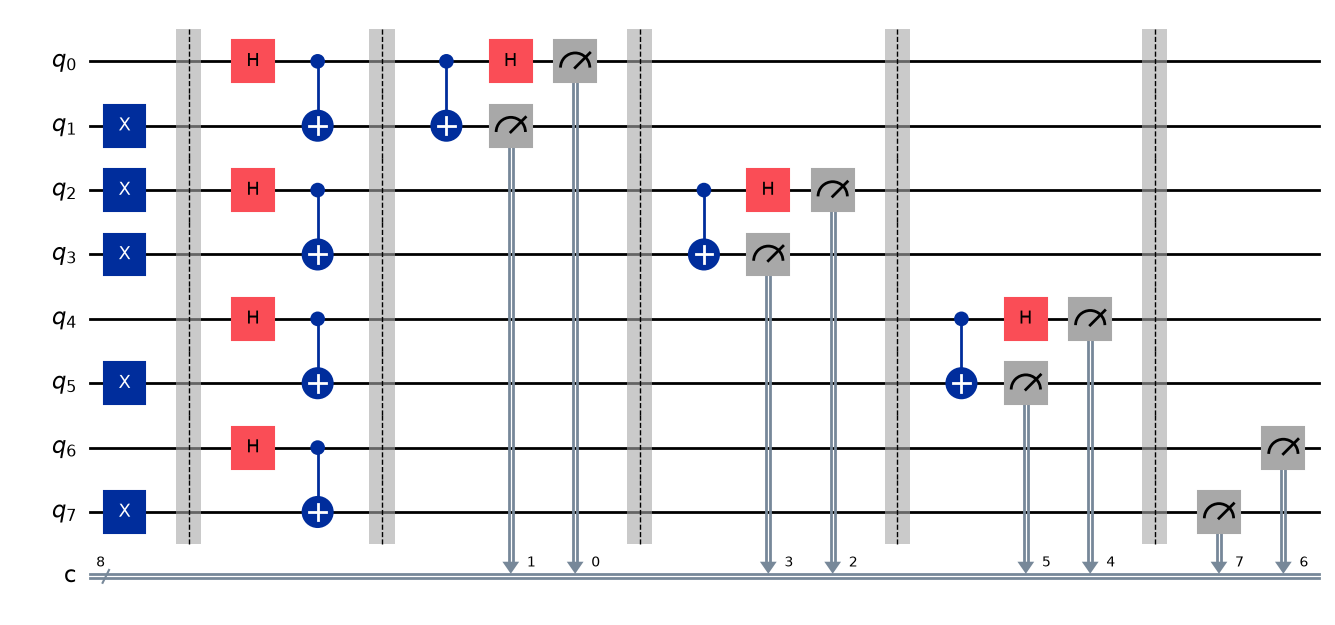

Fig 3 Counts (8192 shots): {'01101110': 4056, '10101110': 4136}

=================== FIG 4: SP -> SM Message Transmission ===================


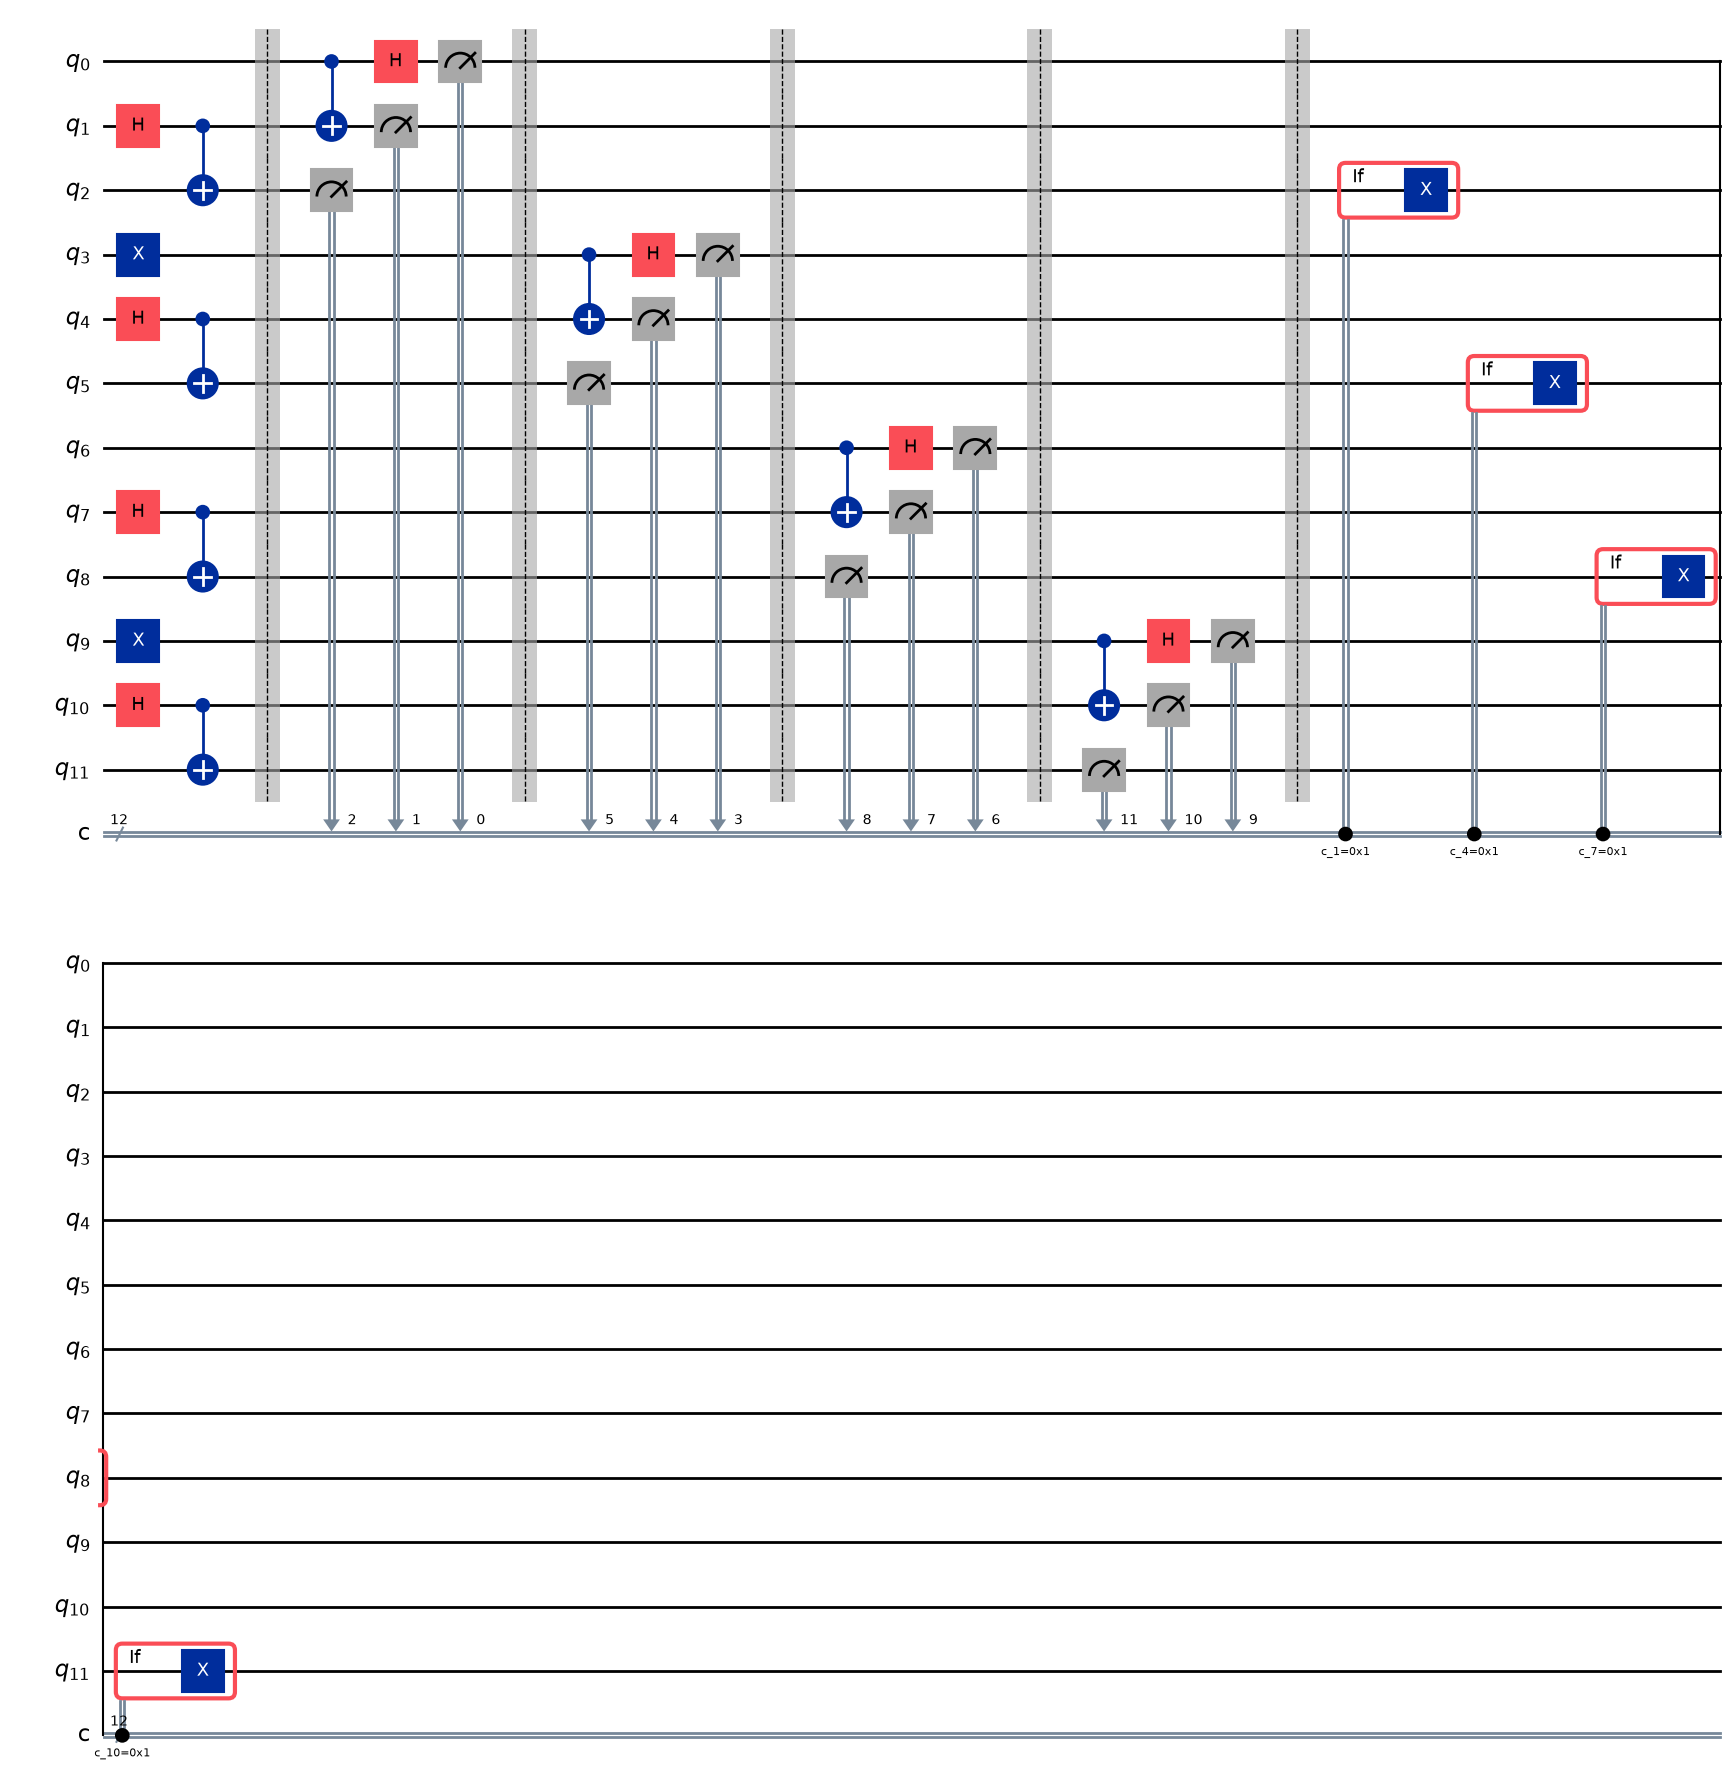

,Mode,Classical Decode Rate,Final State Receiver Match
0,without,100.00%,535 / 8192 (6.53%)
1,static_as_drawn,100.00%,552 / 8192 (6.74%)
2,dynamic,100.00%,8192 / 8192 (100.00%)



=================== FIG 5: SM -> SP Message Transmission ===================


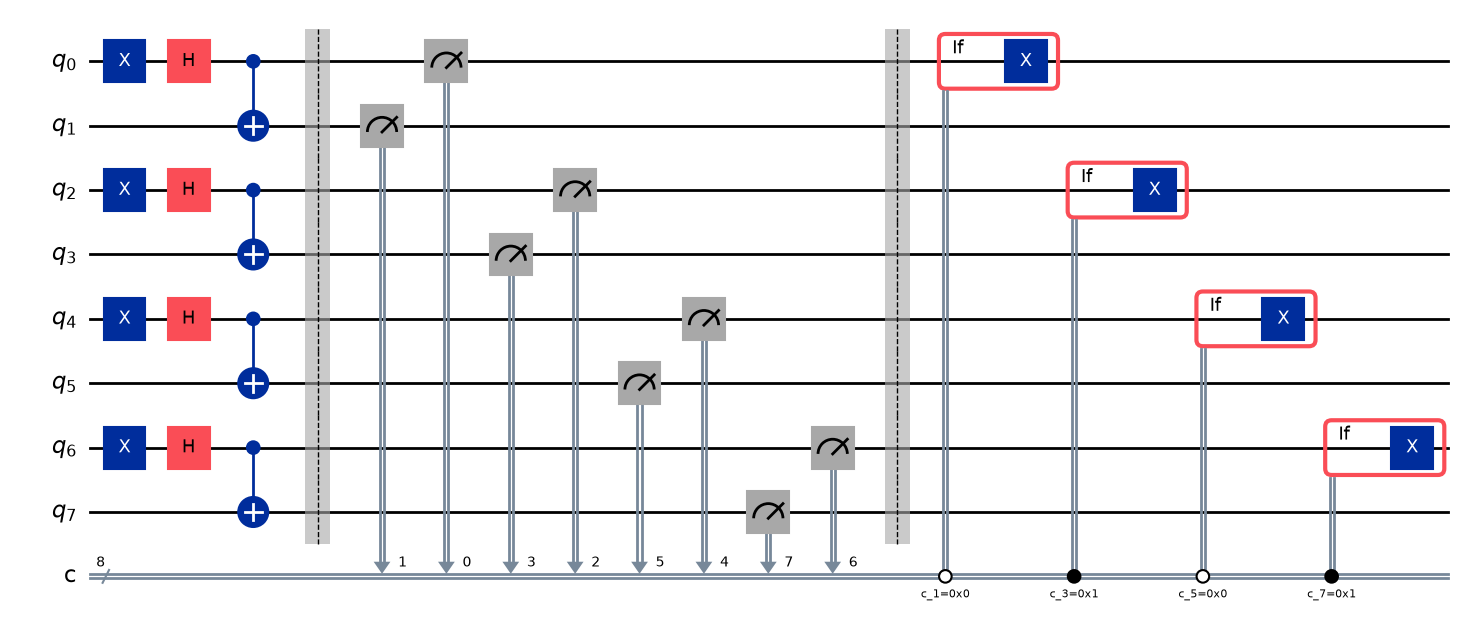

,Mode,Classical Decode Rate,Final State Receiver Match
0,without,100.00%,494 / 8192 (6.03%)
1,static_as_drawn,100.00%,498 / 8192 (6.08%)
2,dynamic,100.00%,8192 / 8192 (100.00%)


In [11]:
# 6. Section V-B: Quantum Circuit Builders & Ideal Simulations (Figs 3-5)
def bsm(qc, a, b, c_a, c_b):
    qc.cx(a, b); qc.h(a)
    qc.measure(b, c_b); qc.measure(a, c_a)

def _sep(qc): qc.barrier()

# Fig. 3: Identity Authentication Circuit (8 qubits, Eq. 15 & Fig. 3)
def fig3():
    qc = QuantumCircuit(8, 8)
    # Stage 1: Single-qubit state preparation
    qc.x(1); qc.x(2); qc.x(3); qc.x(5); qc.x(7)
    qc.barrier()
    # Stage 2: Bell state entanglement generation
    for i in range(4):
        qc.h(2*i); qc.cx(2*i, 2*i+1)
    qc.barrier()
    # Stage 3: Subset A BSM on Pairs 0, 1, 2
    for i in range(3):
        a, b = 2*i, 2*i+1
        qc.cx(a, b); qc.h(a)
        qc.measure(b, b); qc.measure(a, a)
        qc.barrier()
    # Stage 4: Subset B ZBM on Pair 3 (q6, q7)
    qc.measure(7, 7); qc.measure(6, 6)
    return qc

# Fig. 4: SP -> SM Quantum Message Transmission Circuit (12 qubits, Eq. 16)
def fig4(omega_sp=(1, 0, 0, 1), mode="without"):
    qc = QuantumCircuit(12, 12)
    for i, w in enumerate(omega_sp):
        if w: qc.x(3*i)
        prep_bell(qc, 3*i+1, 3*i+2, "Psi+")
    for i in range(4):
        w, s3, s4 = 3*i, 3*i+1, 3*i+2
        _sep(qc)
        qc.cx(w, s3); qc.measure(s4, s4)
        qc.h(w); qc.measure(s3, s3); qc.measure(w, w)
    _sep(qc)
    if mode == "static_as_drawn":
        for i, g in enumerate(("I", "X", "I", "X")):
            qc.id(3*i+2) if g == "I" else qc.x(3*i+2)
    elif mode == "dynamic":
        for i in range(4):
            with qc.if_test((qc.clbits[3*i+1], 1)):
                qc.x(3*i+2)
    elif mode != "without":
        raise ValueError(mode)
    return qc

def decode_fig4(bitstring):
    c = [int(x) for x in bitstring.replace(" ", "")[::-1]]
    om, labs = [], []
    for i in range(4):
        m_w, m_s3, s4 = c[3*i], c[3*i+1], c[3*i+2]
        labs.append(BSM_LABEL[(m_w, m_s3)]); om.append(s4 ^ m_s3)
    return om, labs

# Fig. 5: SM -> SP Message Transmission Circuit (8 qubits, Eq. 17)
def fig5(omega_sm=(0, 1, 1, 0), mode="without"):
    qc = QuantumCircuit(8, 8)
    for i in range(4):
        prep_bell(qc, 2*i, 2*i+1, "Psi-")
    _sep(qc)
    for i in range(4):
        qc.measure(2*i+1, 2*i+1); qc.measure(2*i, 2*i)
    _sep(qc)
    if mode == "static_as_drawn":
        for i in range(4): qc.x(2*i+1)
    elif mode == "dynamic":
        for i, w in enumerate(omega_sm):
            with qc.if_test((qc.clbits[2*i+1], 1 - w)):
                qc.x(2*i)
    elif mode != "without":
        raise ValueError(mode)
    return qc

def decode_fig5(bitstring, omega_sm=(0, 1, 1, 0)):
    c = [int(x) for x in bitstring.replace(" ", "")[::-1]]
    out = []
    for i, w in enumerate(omega_sm):
        r5, r6 = c[2*i], c[2*i+1]
        out.append(r5 ^ (1 if w != r6 else 0))
    return out

def with_final_readout(qc):
    out = qc.copy()
    fin = ClassicalRegister(qc.num_qubits, "final")
    out.add_register(fin)
    out.measure(range(qc.num_qubits), fin)
    return out

# Execute Ideal Circuits on AerSimulator
sim = AerSimulator()

print("=================== FIG 3: Identity Authentication ===================")
qc3 = fig3()
fig3_img = qc3.draw("mpl")
fig3_img.savefig("out/fig3.png", dpi=150)
display(fig3_img)

counts3 = sim.run(transpile(qc3, sim), shots=SHOTS, seed_simulator=SEED).result().get_counts()
print(f"Fig 3 Counts (8192 shots): {counts3}")
assert set(counts3.keys()).issubset({"10101110", "01101110"}), f"Unexpected counts: {counts3}"

print("\n=================== FIG 4: SP -> SM Message Transmission ===================")
fig4_results = []
for mode in ("without", "static_as_drawn", "dynamic"):
    qc4 = fig4(omega_sp=[int(b) for b in OMEGA_SP], mode=mode)
    img = qc4.draw("mpl")
    img.savefig(f"out/fig4_{mode}.png", dpi=150)
    if mode == "dynamic":
        display(img)
    
    c_orig = sim.run(transpile(qc4, sim), shots=SHOTS, seed_simulator=SEED).result().get_counts()
    decode_correct = sum(v for k, v in c_orig.items() if decode_fig4(k)[0] == [int(b) for b in OMEGA_SP])
    
    qc4_fin = with_final_readout(qc4)
    c_fin = sim.run(transpile(qc4_fin, sim), shots=SHOTS, seed_simulator=SEED).result().get_counts()
    final_receiver_correct = sum(v for k, v in c_fin.items() if [int(k.split()[0][::-1][idx]) for idx in [2, 5, 8, 11]] == [int(b) for b in OMEGA_SP])
            
    fig4_results.append({
        "Mode": mode,
        "Classical Decode Rate": f"{decode_correct / SHOTS * 100:.2f}%",
        "Final State Receiver Match": f"{final_receiver_correct} / {SHOTS} ({final_receiver_correct / SHOTS * 100:.2f}%)"
    })
display(pd.DataFrame(fig4_results))

print("\n=================== FIG 5: SM -> SP Message Transmission ===================")
fig5_results = []
for mode in ("without", "static_as_drawn", "dynamic"):
    qc5 = fig5(omega_sm=[int(b) for b in OMEGA_SM], mode=mode)
    img = qc5.draw("mpl")
    img.savefig(f"out/fig5_{mode}.png", dpi=150)
    if mode == "dynamic":
        display(img)
    
    c_orig = sim.run(transpile(qc5, sim), shots=SHOTS, seed_simulator=SEED).result().get_counts()
    decode_correct = sum(v for k, v in c_orig.items() if decode_fig5(k, [int(b) for b in OMEGA_SM]) == [int(b) for b in OMEGA_SM])
            
    qc5_fin = with_final_readout(qc5)
    c_fin = sim.run(transpile(qc5_fin, sim), shots=SHOTS, seed_simulator=SEED).result().get_counts()
    final_receiver_correct = sum(v for k, v in c_fin.items() if [int(k.split()[0][::-1][idx]) for idx in [0, 2, 4, 6]] == [int(b) for b in OMEGA_SM])
            
    fig5_results.append({
        "Mode": mode,
        "Classical Decode Rate": f"{decode_correct / SHOTS * 100:.2f}%",
        "Final State Receiver Match": f"{final_receiver_correct} / {SHOTS} ({final_receiver_correct / SHOTS * 100:.2f}%)"
    })
display(pd.DataFrame(fig5_results))


Running Fig 6 benchmark on FakeQuito...


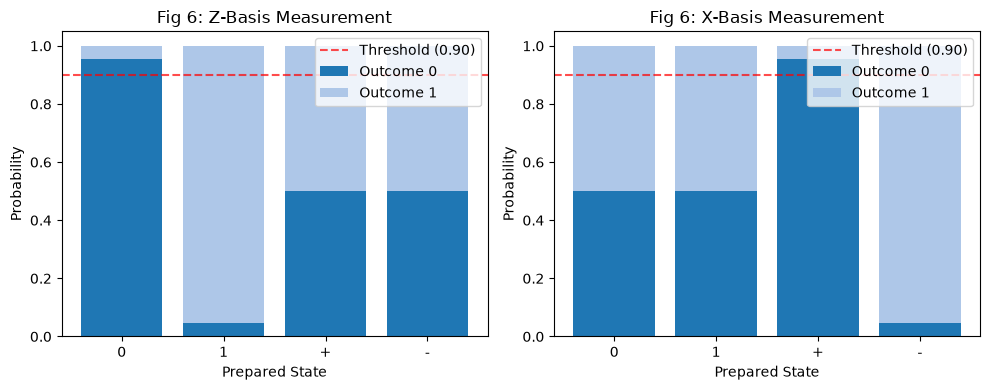

Running Fig 7 benchmark on FakeQuito...


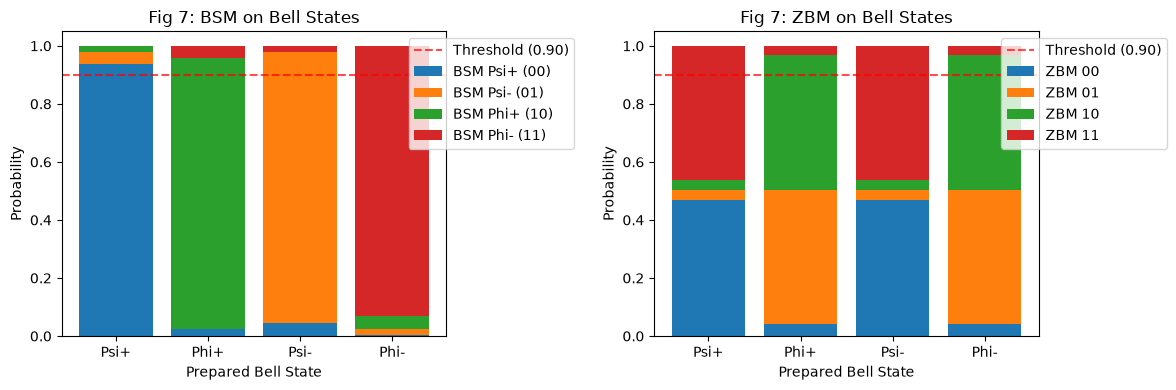

Running Fig 8 benchmark on FakeQuito...


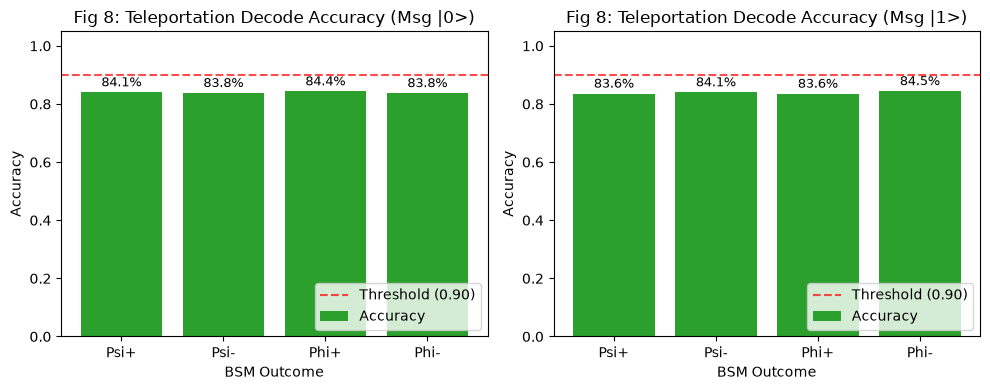

Noisy benchmarks completed and saved to out


In [12]:
# 7. Section V-C: Noisy Micro-Benchmarks on IBM Quantum FakeQuito Backend (Figs 6-8)
def fig6_circuit(prep, basis):
    qc = QuantumCircuit(1, 1)
    if prep in ("1", "-"): qc.x(0)
    if prep in ("+", "-"): qc.h(0)
    if basis == "X": qc.h(0)
    qc.measure(0, 0)
    return qc

def fig7_circuit(label, meas):
    qc = QuantumCircuit(2, 2)
    prep_bell(qc, 0, 1, label)
    if meas == "BSM": bsm(qc, 0, 1, 0, 1)
    else: qc.measure([0, 1], [0, 1])
    return qc

def fig8_circuit(msg):
    qc = QuantumCircuit(3, 3)
    if msg: qc.x(0)
    prep_bell(qc, 1, 2, "Psi+")
    qc.barrier()
    qc.cx(0, 1); qc.h(0)
    qc.measure(0, 0); qc.measure(1, 1); qc.measure(2, 2)
    return qc

be = FakeQuitoV2()
sim_noisy = AerSimulator.from_backend(be)

def run_noisy(qc, layout):
    t = transpile(qc, be, initial_layout=layout, optimization_level=1, seed_transpiler=42)
    return sim_noisy.run(t, shots=SHOTS, seed_simulator=7).result().get_counts()

print("Running Fig 6 benchmark on FakeQuito...")
fig6_data = []
for basis in ("Z", "X"):
    for prep in ("0", "1", "+", "-"):
        c = run_noisy(fig6_circuit(prep, basis), [0])
        p0 = c.get("0", 0) / SHOTS
        p1 = c.get("1", 0) / SHOTS
        fig6_data.append({"Basis": basis, "Prepared": prep, "Prob_0": p0, "Prob_1": p1})

df_fig6 = pd.DataFrame(fig6_data)
df_fig6.to_csv("out/fig6_noisy.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, basis in zip(axes, ("Z", "X")):
    sub = df_fig6[df_fig6["Basis"] == basis]
    x = np.arange(len(sub))
    ax.bar(x, sub["Prob_0"], label="Outcome 0", color="#1f77b4")
    ax.bar(x, sub["Prob_1"], bottom=sub["Prob_0"], label="Outcome 1", color="#aec7e8")
    ax.set_xticks(x)
    ax.set_xticklabels(sub["Prepared"])
    ax.set_title(f"Fig 6: {basis}-Basis Measurement")
    ax.set_xlabel("Prepared State")
    ax.set_ylabel("Probability")
    ax.set_ylim(0, 1.05)
    ax.axhline(0.90, color="red", linestyle="--", alpha=0.7, label="Threshold (0.90)")
    ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("out/fig6_noisy.png", dpi=150)
plt.show()

print("Running Fig 7 benchmark on FakeQuito...")
fig7_data = []
bell_order = ["Psi+", "Phi+", "Psi-", "Phi-"]
for meas in ("BSM", "ZBM"):
    for lab in bell_order:
        c = run_noisy(fig7_circuit(lab, meas), [0, 1])
        row = {"Meas": meas, "State": lab}
        for code in ("00", "01", "10", "11"):
            row[f"Prob_{code}"] = c.get(code, 0) / SHOTS
        fig7_data.append(row)

df_fig7 = pd.DataFrame(fig7_data)
df_fig7.to_csv("out/fig7_noisy.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
for ax, meas in zip(axes, ("BSM", "ZBM")):
    sub = df_fig7[df_fig7["Meas"] == meas]
    x = np.arange(len(sub))
    bottom = np.zeros(len(sub))
    for idx, code in enumerate(("00", "01", "10", "11")):
        probs = sub[f"Prob_{code}"].values
        label_text = f"BSM {BSM_LABEL.get((int(code[1]), int(code[0])), code)} ({code})" if meas=="BSM" else f"ZBM {code}"
        ax.bar(x, probs, bottom=bottom, label=label_text, color=colors[idx])
        bottom += probs
    ax.set_xticks(x)
    ax.set_xticklabels(sub["State"])
    ax.set_title(f"Fig 7: {meas} on Bell States")
    ax.set_xlabel("Prepared Bell State")
    ax.set_ylabel("Probability")
    ax.set_ylim(0, 1.05)
    ax.axhline(0.90, color="red", linestyle="--", alpha=0.7, label="Threshold (0.90)")
    ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.0))
plt.tight_layout()
plt.savefig("out/fig7_noisy.png", dpi=150)
plt.show()

print("Running Fig 8 benchmark on FakeQuito...")
fig8_rows = []
for msg in (0, 1):
    c = run_noisy(fig8_circuit(msg), [0, 1, 2])
    outcome_stats = {l: {"correct": 0, "wrong": 0, "total": 0} for l in ("Psi+", "Psi-", "Phi+", "Phi-")}
    for k, v in c.items():
        b = [int(x) for x in k[::-1]]
        outcome = BSM_LABEL[(b[0], b[1])]
        decoded = b[2] ^ b[1]
        outcome_stats[outcome]["total"] += v
        if decoded == msg:
            outcome_stats[outcome]["correct"] += v
        else:
            outcome_stats[outcome]["wrong"] += v
    for lab in ("Psi+", "Psi-", "Phi+", "Phi-"):
        tot = outcome_stats[lab]["total"]
        corr = outcome_stats[lab]["correct"] / tot if tot > 0 else 0
        fig8_rows.append({"Message": msg, "BSM_Outcome": lab, "Accuracy": corr, "Total_Shots": tot})

df_fig8 = pd.DataFrame(fig8_rows)
df_fig8.to_csv("out/fig8_noisy.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, msg in zip(axes, (0, 1)):
    sub = df_fig8[df_fig8["Message"] == msg]
    x = np.arange(len(sub))
    ax.bar(x, sub["Accuracy"], color="#2ca02c", label="Accuracy")
    ax.set_xticks(x)
    ax.set_xticklabels(sub["BSM_Outcome"])
    ax.set_title(f"Fig 8: Teleportation Decode Accuracy (Msg |{msg}>)")
    ax.set_xlabel("BSM Outcome")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1.05)
    ax.axhline(0.90, color="red", linestyle="--", alpha=0.7, label="Threshold (0.90)")
    for i, v in enumerate(sub["Accuracy"]):
        ax.text(i, v + 0.02, f"{v*100:.1f}%", ha="center", fontsize=9)
    ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("out/fig8_noisy.png", dpi=150)
plt.show()

print("Noisy benchmarks completed and saved to out")


In [13]:
# 8. Standalone BB84-Style Intercept-and-Resend Attack Simulation
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def run_decoy_attack_test(shots=2000, seed=42):
    """
    Standalone BB84-style intercept-and-resend experiment.
    This is not the complete semi-quantum BDT protocol.
    """
    rng = np.random.default_rng(seed)
    simulator = AerSimulator()
    results = {}

    for attack in (False, True):
        errors = 0

        for _ in range(shots):
            # Randomly choose a BB84 state.
            state = rng.choice(["0", "1", "+", "-"])
            prep_basis = "X" if state in ("+", "-") else "Z"
            expected = int(state in ("1", "-"))

            # Two classical bits:
            # c[0] records Eve's measurement; c[1] records receiver's.
            qc = QuantumCircuit(1, 2)

            # Prepare the original state.
            if state in ("1", "-"):
                qc.x(0)
            if state in ("+", "-"):
                qc.h(0)

            if attack:
                # Eve randomly chooses a measurement basis.
                eve_basis = rng.choice(["Z", "X"])

                if eve_basis == "X":
                    qc.h(0)

                qc.measure(0, 0)

                # Reset the qubit once, then resend Eve's result.
                qc.reset(0)

                with qc.if_test((qc.clbits[0], 1)):
                    qc.x(0)

                # Recreate the state in Eve's measurement basis.
                if eve_basis == "X":
                    qc.h(0)

            # The legitimate receiver measures in the preparation basis.
            if prep_basis == "X":
                qc.h(0)

            qc.measure(0, 1)

            result = simulator.run(
                qc,
                shots=1,
                seed_simulator=int(rng.integers(0, 2**31 - 1))
            ).result()

            bitstring = next(iter(result.get_counts()))
            bits = bitstring.replace(" ", "")
            receiver_bit = int(bits[0])

            if receiver_bit != expected:
                errors += 1

        results["attack" if attack else "no_attack"] = errors / shots

    return results


print(run_decoy_attack_test(shots=2000, seed=42))


{'no_attack': 0.0, 'attack': 0.2495}
